In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
train_df=pd.read_csv('train.csv')

In [4]:
train_df.shape

(1460, 81)

In [5]:
train_df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

In [7]:
train_df.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [8]:
num_df=train_df.select_dtypes(include='number')

In [9]:
str_df=train_df.select_dtypes(include='string')

In [10]:
num_df.shape

(1460, 38)

In [11]:
str_df.shape

(1460, 43)

In [12]:
str_df

,MSZoning,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,...,GarageType,GarageFinish,GarageQual,GarageCond,PavedDrive,PoolQC,Fence,MiscFeature,SaleType,SaleCondition
0,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
1,RL,Pave,NaN,Reg,Lvl,AllPub,FR2,Gtl,Veenker,Feedr,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
2,RL,Pave,NaN,IR1,Lvl,AllPub,Inside,Gtl,CollgCr,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
3,RL,Pave,NaN,IR1,Lvl,AllPub,Corner,Gtl,Crawfor,Norm,...,Detchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Abnorml
4,RL,Pave,NaN,IR1,Lvl,AllPub,FR2,Gtl,NoRidge,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Gilbert,Norm,...,Attchd,RFn,TA,TA,Y,NaN,NaN,NaN,WD,Normal
1456,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NWAmes,Norm,...,Attchd,Unf,TA,TA,Y,NaN,MnPrv,NaN,WD,Normal
1457,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,Crawfor,Norm,...,Attchd,RFn,TA,TA,Y,NaN,GdPrv,Shed,WD,Normal
1458,RL,Pave,NaN,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,...,Attchd,Unf,TA,TA,Y,NaN,NaN,NaN,WD,Normal


<Axes: >

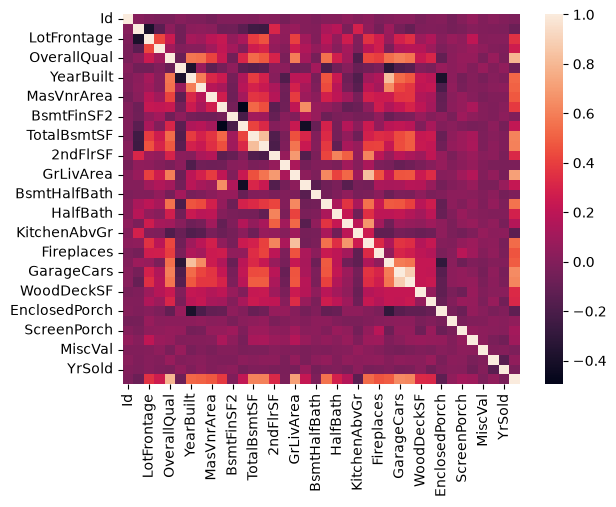

In [14]:
sns.heatmap(num_df.corr())

In [13]:
num_df

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
0,1,60,65.0,8450,7,5,2003,2003,196.0,706,...,0,61,0,0,0,0,0,2,2008,208500
1,2,20,80.0,9600,6,8,1976,1976,0.0,978,...,298,0,0,0,0,0,0,5,2007,181500
2,3,60,68.0,11250,7,5,2001,2002,162.0,486,...,0,42,0,0,0,0,0,9,2008,223500
3,4,70,60.0,9550,7,5,1915,1970,0.0,216,...,0,35,272,0,0,0,0,2,2006,140000
4,5,60,84.0,14260,8,5,2000,2000,350.0,655,...,192,84,0,0,0,0,0,12,2008,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,62.0,7917,6,5,1999,2000,0.0,0,...,0,40,0,0,0,0,0,8,2007,175000
1456,1457,20,85.0,13175,6,6,1978,1988,119.0,790,...,349,0,0,0,0,0,0,2,2010,210000
1457,1458,70,66.0,9042,7,9,1941,2006,0.0,275,...,0,60,0,0,0,0,2500,5,2010,266500
1458,1459,20,68.0,9717,5,6,1950,1996,0.0,49,...,366,0,112,0,0,0,0,4,2010,142125


In [14]:
num_df.isnull().sum()

Id                 0
MSSubClass         0
LotFrontage      259
LotArea            0
OverallQual        0
OverallCond        0
YearBuilt          0
YearRemodAdd       0
MasVnrArea         8
BsmtFinSF1         0
BsmtFinSF2         0
BsmtUnfSF          0
TotalBsmtSF        0
1stFlrSF           0
2ndFlrSF           0
LowQualFinSF       0
GrLivArea          0
BsmtFullBath       0
BsmtHalfBath       0
FullBath           0
HalfBath           0
BedroomAbvGr       0
KitchenAbvGr       0
TotRmsAbvGrd       0
Fireplaces         0
GarageYrBlt       81
GarageCars         0
GarageArea         0
WoodDeckSF         0
OpenPorchSF        0
EnclosedPorch      0
3SsnPorch          0
ScreenPorch        0
PoolArea           0
MiscVal            0
MoSold             0
YrSold             0
SalePrice          0
dtype: int64

In [15]:
num_df.corr()['SalePrice']

Id              -0.021917
MSSubClass      -0.084284
LotFrontage      0.351799
LotArea          0.263843
OverallQual      0.790982
OverallCond     -0.077856
YearBuilt        0.522897
YearRemodAdd     0.507101
MasVnrArea       0.477493
BsmtFinSF1       0.386420
BsmtFinSF2      -0.011378
BsmtUnfSF        0.214479
TotalBsmtSF      0.613581
1stFlrSF         0.605852
2ndFlrSF         0.319334
LowQualFinSF    -0.025606
GrLivArea        0.708624
BsmtFullBath     0.227122
BsmtHalfBath    -0.016844
FullBath         0.560664
HalfBath         0.284108
BedroomAbvGr     0.168213
KitchenAbvGr    -0.135907
TotRmsAbvGrd     0.533723
Fireplaces       0.466929
GarageYrBlt      0.486362
GarageCars       0.640409
GarageArea       0.623431
WoodDeckSF       0.324413
OpenPorchSF      0.315856
EnclosedPorch   -0.128578
3SsnPorch        0.044584
ScreenPorch      0.111447
PoolArea         0.092404
MiscVal         -0.021190
MoSold           0.046432
YrSold          -0.028923
SalePrice        1.000000
Name: SalePr

<Axes: xlabel='GarageCars', ylabel='SalePrice'>

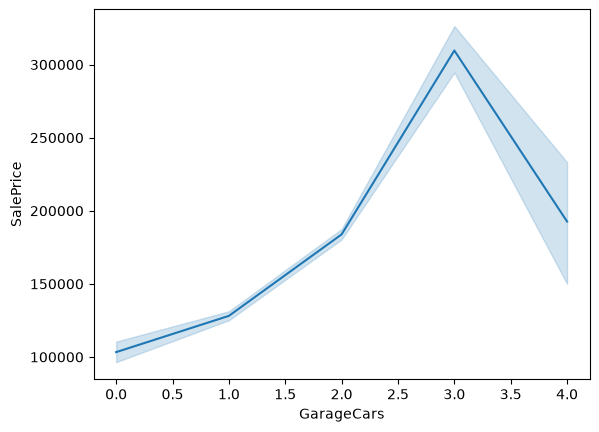

In [187]:
# 61  GarageCars     1460 non-null   int64  
#  62  GarageArea
sns.lineplot(x=train_df['GarageCars'],y=train_df['SalePrice'])

C:\Users\RITIKA\AppData\Local\Temp\ipykernel_15952\1230359480.py:2: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


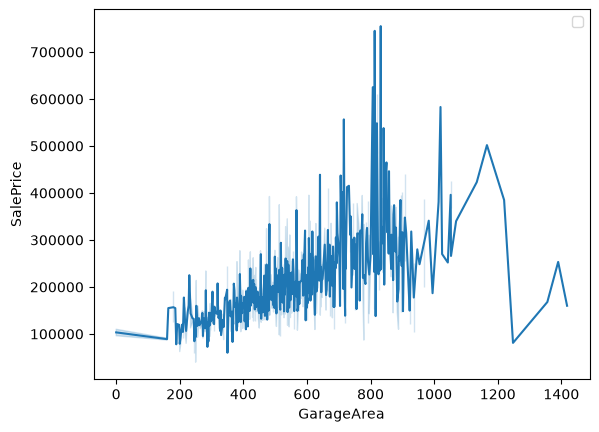

In [188]:
sns.lineplot(x=train_df['GarageArea'],y=train_df['SalePrice'])
plt.legend()
plt.show()

In [16]:
# keeping only releevant columns
x=train_df.iloc[:,[3,4,17,18,38,46,49,50,61,19,20,43,12]]

In [17]:
x

,LotFrontage,LotArea,OverallQual,OverallCond,TotalBsmtSF,GrLivArea,FullBath,HalfBath,GarageCars,YearBuilt,YearRemodAdd,1stFlrSF,Neighborhood
0,65.0,8450,7,5,856,1710,2,1,2,2003,2003,856,CollgCr
1,80.0,9600,6,8,1262,1262,2,0,2,1976,1976,1262,Veenker
2,68.0,11250,7,5,920,1786,2,1,2,2001,2002,920,CollgCr
3,60.0,9550,7,5,756,1717,1,0,3,1915,1970,961,Crawfor
4,84.0,14260,8,5,1145,2198,2,1,3,2000,2000,1145,NoRidge
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,62.0,7917,6,5,953,1647,2,1,2,1999,2000,953,Gilbert
1456,85.0,13175,6,6,1542,2073,2,0,2,1978,1988,2073,NWAmes
1457,66.0,9042,7,9,1152,2340,2,0,1,1941,2006,1188,Crawfor
1458,68.0,9717,5,6,1078,1078,1,0,1,1950,1996,1078,NAmes


In [18]:
y=train_df.iloc[:,-1]

In [19]:
y

0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SalePrice, Length: 1460, dtype: int64

<BarContainer object of 1460 artists>

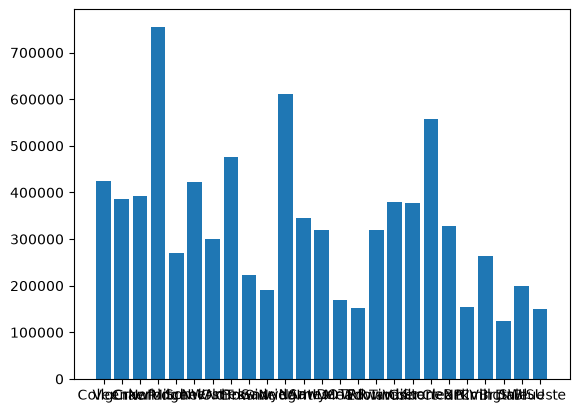

In [193]:
plt.bar(x['Neighborhood'],y)

In [194]:
x['Neighborhood'].groupby(x['Neighborhood']).count()

Neighborhood
Blmngtn     17
Blueste      2
BrDale      16
BrkSide     58
ClearCr     28
CollgCr    150
Crawfor     51
Edwards    100
Gilbert     79
IDOTRR      37
MeadowV     17
Mitchel     49
NAmes      225
NPkVill      9
NWAmes      73
NoRidge     41
NridgHt     77
OldTown    113
SWISU       25
Sawyer      74
SawyerW     59
Somerst     86
StoneBr     25
Timber      38
Veenker     11
Name: Neighborhood, dtype: int64

In [150]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.25,random_state=42)

In [151]:
# checking null values
x.isnull().sum()

LotFrontage     259
LotArea           0
OverallQual       0
OverallCond       0
TotalBsmtSF       0
GrLivArea         0
FullBath          0
HalfBath          0
GarageCars        0
YearBuilt         0
YearRemodAdd      0
1stFlrSF          0
Neighborhood      0
dtype: int64

In [152]:

from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

In [23]:
# imputing missing value with median and encoding neighborhood
t=ColumnTransformer(transformers=[
    ('trf1',SimpleImputer(strategy='median'),['LotFrontage']),
    ('trf2',OneHotEncoder(drop='first', handle_unknown='ignore'),['Neighborhood'])
], remainder='passthrough')

In [153]:
x_train,x_test,y_train,y_test=train_test_split(x.drop(['YearBuilt'],axis=1),y,test_size=0.25,random_state=42)
log_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('log', FunctionTransformer(np.log1p))
])

t = ColumnTransformer(transformers=[
    ('trf1', log_transformer, ['LotFrontage', 'LotArea']),
    ('trf2', OneHotEncoder(drop='first', handle_unknown='ignore'),
     ['Neighborhood'])
], remainder='passthrough')

In [154]:
t.fit_transform(x_train)
t.transform(x_test)

array([[4.26267988e+00, 9.03777111e+00, 0.00000000e+00, ...,
        1.00000000e+00, 2.00300000e+03, 1.06800000e+03],
       [4.59511985e+00, 9.41385248e+00, 0.00000000e+00, ...,
        2.00000000e+00, 1.99500000e+03, 1.50000000e+03],
       [4.04305127e+00, 9.10063711e+00, 0.00000000e+00, ...,
        2.00000000e+00, 1.95000000e+03, 1.02800000e+03],
       ...,
       [4.26821962e+00, 9.14590851e+00, 0.00000000e+00, ...,
        2.00000000e+00, 2.00200000e+03, 1.28400000e+03],
       [4.26821962e+00, 1.03076184e+01, 0.00000000e+00, ...,
        2.00000000e+00, 1.99400000e+03, 9.79000000e+02],
       [4.27666612e+00, 9.12750209e+00, 0.00000000e+00, ...,
        1.00000000e+00, 1.96300000e+03, 1.14400000e+03]], shape=(365, 35))

In [171]:
X_train_transformed = t.fit_transform(x_train)

In [172]:
X_test_transformed = t.transform(x_test)

In [173]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()

In [174]:
lr.fit(X_train_transformed,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](35,)","[-2918.67,25485.22, 1123.92,...,11957.34, 271.07, 9.61]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.9e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(35)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](35,)","[22263.69,12539.09, 5528.07,..., 2.51, 1.02, 0.71]"


In [175]:
y_pred=lr.predict(X_test_transformed)
y_train_pred = lr.predict(X_train_transformed)

In [176]:
# r2 score 1
from sklearn.metrics import r2_score
new=r2_score(y_test,y_pred)
n1 = r2_score(y_train, y_train_pred)

In [178]:
new,n1

(0.8451588312984047, 0.8173730967107141)

<Axes: xlabel='OverallCond', ylabel='Count'>

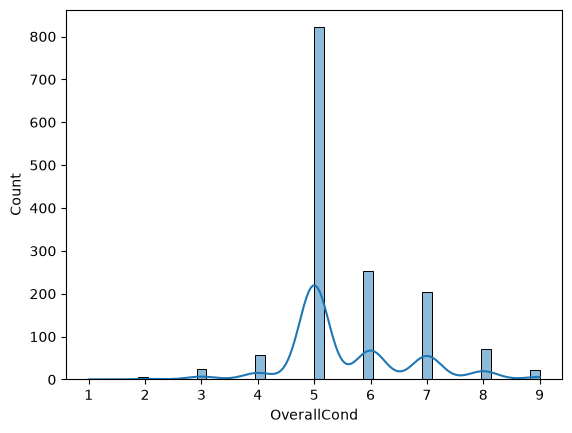

In [31]:
sns.histplot(x['OverallCond'],kde=True)

In [164]:
#log transform
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline
log_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p))
])

t = ColumnTransformer(transformers=[
    ('trf1', log_transformer, ['LotFrontage', 'LotArea']),
    ('trf2', OneHotEncoder(drop='first', handle_unknown='ignore'),
     ['Neighborhood'])
], remainder='passthrough')

In [165]:
X_train_transformed = t.fit_transform(x_train)

In [166]:
X_test_transformed = t.transform(x_test)

In [167]:
lr.fit(X_train_transformed,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](35,)","[-2918.67,25485.22, 1123.92,...,11957.34, 271.07, 9.61]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-7.9e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(35)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](35,)","[22263.69,12539.09, 5528.07,..., 2.51, 1.02, 0.71]"


In [168]:
y_pred=y_pred=lr.predict(X_test_transformed)
y_train_pred = lr.predict(X_train_transformed)
# r2 score 2
n2 = r2_score(y_train, y_train_pred)

In [169]:
new1=r2_score(y_test,y_pred)

In [170]:
new,new1

(0.6756045968662582, 0.8451588312984047)

In [39]:
# with some columns

In [40]:
x_train,x_test,y_train,y_test=train_test_split(x.drop(['YearBuilt'],axis=1),y,test_size=0.25,random_state=2)

In [41]:
x_train.describe()

,LotFrontage,LotArea,OverallQual,OverallCond,TotalBsmtSF,GrLivArea,FullBath,HalfBath,GarageCars,YearRemodAdd,1stFlrSF
count,906.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000,1095.000000
mean,69.843267,10409.499543,6.054795,5.571689,1042.116895,1502.320548,1.557991,0.374429,1.754338,1984.501370,1152.663927
std,23.779413,10000.766548,1.371128,1.119922,406.325865,494.189374,0.547612,0.497236,0.746054,20.693015,364.826322
min,21.000000,1477.000000,1.000000,1.000000,0.000000,334.000000,0.000000,0.000000,0.000000,1950.000000,334.000000
25%,59.000000,7500.000000,5.000000,5.000000,791.500000,1123.500000,1.000000,0.000000,1.000000,1966.000000,884.000000
50%,69.000000,9382.000000,6.000000,5.000000,990.000000,1466.000000,2.000000,0.000000,2.000000,1993.000000,1078.000000
75%,80.000000,11450.000000,7.000000,6.000000,1289.500000,1768.000000,2.000000,1.000000,2.000000,2003.000000,1386.000000
max,313.000000,215245.000000,10.000000,9.000000,3094.000000,4476.000000,3.000000,2.000000,4.000000,2010.000000,2898.000000


In [42]:
log_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log', FunctionTransformer(np.log1p))
])

t = ColumnTransformer(transformers=[
    ('trf1', log_transformer, ['LotFrontage', 'LotArea']),
    ('trf2', OneHotEncoder(drop='first', handle_unknown='ignore'),
     ['Neighborhood'])
], remainder='passthrough')

In [43]:
X_train_transformed = t.fit_transform(x_train)

In [44]:
X_test_transformed = t.transform(x_test)

In [45]:
lr.fit(X_train_transformed,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](35,)","[ 7004.47,21898.02, 9694.66,..., 9057.34, 313.95, 7.71]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-8.985e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,35
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(35)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](35,)","[20262.84,12303.46, 5614.02,..., 2.51, 1.02, 0.69]"


In [161]:
y_pred=y_pred=lr.predict(X_test_transformed)
y_train_pred = lr.predict(X_train_transformed)
# r2 score 3
n3 = r2_score(y_train, y_train_pred)

In [162]:
new2=r2_score(y_test,y_pred)

In [163]:
new,n1,new1,n2,new2,n3

(0.6756045968662582,
 0.8603255626198327,
 0.7088859699906938,
 0.8626793176950017,
 0.8451539205415705,
 0.817373686922405)

In [49]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2 score",r2_score(y_test,y_pred))

MAE 22610.57047480893
MSE 2001798162.0963035
R2 score 0.7171721945158398


### # gradient descent with standard scaler 

<Axes: ylabel='LotFrontage'>

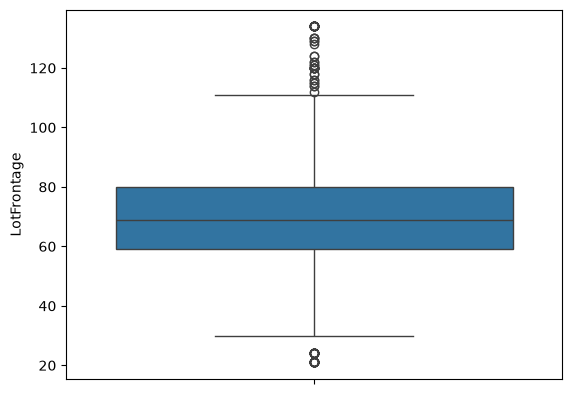

In [301]:

sns.boxplot(x['LotFrontage'])

In [303]:
x.isnull().mean()*100

LotFrontage     17.739726
LotArea          0.000000
OverallQual      0.000000
OverallCond      0.000000
TotalBsmtSF      0.000000
GrLivArea        0.000000
FullBath         0.000000
HalfBath         0.000000
GarageCars       0.000000
YearBuilt        0.000000
YearRemodAdd     0.000000
1stFlrSF         0.000000
Neighborhood     0.000000
dtype: float64

C:\Users\RITIKA\AppData\Local\Temp\ipykernel_23496\2999992013.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x['LotFrontage'])


<Axes: xlabel='LotFrontage', ylabel='Density'>

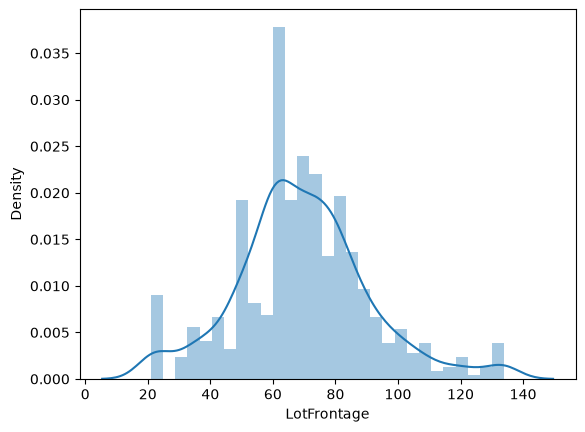

In [304]:
sns.distplot(x['LotFrontage'])

In [300]:
x['LotFrontage'].describe()

count    1201.000000
mean       69.513730
std        21.451315
min        21.000000
25%        59.000000
50%        69.000000
75%        80.000000
max       133.999421
Name: LotFrontage, dtype: float64

In [298]:
upper_limit = x['LotFrontage'].mean() + 3*x['LotFrontage'].std()
lower_limit = x['LotFrontage'].mean() - 3*x['LotFrontage'].std()
upper_limit,lower_limit

(np.float64(133.99942077400368), np.float64(5.054165613811193))

In [299]:
x['LotFrontage'] = np.where(
    x['LotFrontage']>upper_limit,
    upper_limit,
    np.where(
        x['LotFrontage']<lower_limit,
        lower_limit,
        x['LotFrontage']
    )
)

In [302]:

x_train,x_test,y_train,y_test=train_test_split(x.drop(['YearBuilt'],axis=1),y,test_size=0.25,random_state=42)
log_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
    ('log', FunctionTransformer(np.log1p))
])

t = ColumnTransformer(transformers=[
    ('trf1', log_transformer, ['LotFrontage', 'LotArea']),
    ('trf2', OneHotEncoder(drop='first', handle_unknown='ignore'),
     ['Neighborhood'])
], remainder='passthrough')


In [305]:
x_train_tranformed=t.fit_transform(x_train)
x_test_tranformed=t.transform(x_test)

In [307]:
from sklearn.preprocessing import StandardScaler
s=StandardScaler()
x_train_scaled=s.fit_transform(x_train_tranformed)
x_test_scaled=s.transform(x_test_tranformed)

In [308]:
from sklearn.linear_model import SGDRegressor
sgd=SGDRegressor(max_iter=1000,learning_rate='constant',eta0=0.0001,
    random_state=42,tol=0.2)
sgd.fit(x_train_scaled,y_train)
y_pred=sgd.predict(x_test_scaled)

In [309]:
r2_score(y_test,y_pred)

0.8462191052757162

In [310]:
print("Actual:", y_test[:5].values)
print("Predicted:", y_pred[:5])
print("Min prediction:", y_pred.min())
print("Max prediction:", y_pred.max())

Actual: [154500 325000 115000 159000 315500]
Predicted: [152308.21445767 328075.98253346 110956.17563807 165499.18123497
 279678.58863371]
Min prediction: 8409.408025051584
Max prediction: 441971.8022336333


In [311]:
print(y_train.describe())
print(y_train.min(), y_train.max())

count      1095.000000
mean     181712.286758
std       77955.082565
min       34900.000000
25%      130000.000000
50%      165000.000000
75%      215000.000000
max      745000.000000
Name: SalePrice, dtype: float64
34900 745000


In [312]:
print("Train R2:", sgd.score(x_train_scaled, y_train))
print("Test R2:", sgd.score(x_test_scaled, y_test))

Train R2: 0.8325986691026946
Test R2: 0.8462191052757162


In [313]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2 score",r2_score(y_test,y_pred))

MAE 20372.924314951084
MSE 1077282693.888865
R2 score 0.8462191052757162
